# Baseline CD: a reusable four-pulse word

The minimum allowed vacuum swap time is **200 ns**. The current
[fast-gate notebook](modulated_swap200.ipynb) gives a verified
300 ns CD within this limit. This notebook preserves the 370 ns baseline
and its tested signed-beta scaling rule.

Play **X, X, Xbar, Xbar**, each a 30 ns pi pulse, and repeat. Keep the sideband
phase fixed. Three cycles give **CD(beta=1) in 370 ns command time at 99.23%
coherent gate fidelity**. The entire modeled RFDC response is 414.22 ns.

The input space is all g/e × Fock n=0..8 states, including relative phases.
The model has a perfect two-level qubit, no loss and no static chi.
This notebook explains the cancellation during finite pulses, gives the
repeat/strength rule, and compares stronger-sideband alternatives.

In [1]:
# Locate code/ when this notebook is opened from notebooks/ or archive/.
from pathlib import Path as _Path
import sys as _sys
_project=next(p for p in [_Path.cwd(),*_Path.cwd().parents]
              if (p/'code/project_paths.py').is_file())
if str(_project/'code') not in _sys.path:
    _sys.path.insert(0,str(_project/'code'))
from project_paths import ROOT as PROJECT_ROOT, CODE, NOTEBOOKS


import os
os.environ['OPENBLAS_NUM_THREADS']='1'
os.environ['OMP_NUM_THREADS']='1'
import json,hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
import cd_trains as cd
import hardware_check as hw
from acadia.sample_arithmetic import sample_to_complex
ROOT=PROJECT_ROOT;DATA=ROOT/'runs/constant_pump_gaussian';V=DATA/'verified'
FIG=DATA/'figures';FIG.mkdir(exist_ok=True)
def read(name):return json.loads((DATA/name).read_text())
def certificate(name):return json.loads((V/(name+'.json')).read_text())
def source(name):return read(name+'.json')
def finish(name):
    plt.gcf().savefig(FIG/(name+'.png'),dpi=160,bbox_inches='tight');plt.show()
def replay(name):
    r=certificate(name);w=np.load(V/(name+'_words.npz'))
    digest=hashlib.sha256(w['qubit'].tobytes()+w['sideband'].tobytes()).hexdigest()
    assert digest==r['word_sha256']
    qs,ss=hw.dac_scales(.6)
    q=hw.rfdc_interpolate(sample_to_complex(w['qubit'])).conj()/qs*(np.pi/cd.PI_TIME)
    s=hw.rfdc_interpolate(sample_to_complex(w['sideband']))/ss*(np.pi/(2*.6))
    sp=cd.Space(r['levels'],9);initial=np.eye(2*r['levels'],dtype=complex)[:,sp.inputs]
    output=hw.propagate(q,s,initial,cd.DT/8,order=16)
    output*=np.exp(-1j*r['qubit_frame_Rz']*sp.z/2)[:,None]
    saved=np.load(V/(name+'_columns.npz'));target=saved['target']
    difference=float(np.max(abs(output-saved['output'])))
    fidelity=float(abs(np.vdot(target,output)/18)**2)
    assert difference<1e-10 and abs(fidelity-r['fidelity'])<1e-12
    print('FRESH INDEPENDENT REPLAY',name,'18inputcolumns;',output.size,
          'amplitudes;maxdifference',difference,'F',fidelity)
    return r,output,target

simple=certificate('cd_binary_scaled_b1')
refined=certificate('played_cd_n12_pump1_seed0')
display(pd.DataFrame([dict(scheme=label,command_ns=r['command_us']*1000,
                         full_RFDC_window_ns=r['RFDC_window_us']*1000,
                         gate_fidelity=r['fidelity'],worst_basis_fidelity=r['worst_basis_fidelity'])
                      for label,r in [('Fixed pump, four-pulse word',simple),('10ns IQ, corrected phases',refined)]]))


,scheme,command_ns,full_RFDC_window_ns,gate_fidelity,worst_basis_fidelity
0,"Fixed pump, four-pulse word",370.0,414.21875,0.992278,0.979996
1,"10ns IQ, corrected phases",370.0,414.21875,0.993292,0.981043


## 1. Cancel errors while the qubit pulse is on

The target is $\mathrm{CD}(\beta)=e^{\beta\sigma_x(a^\dagger-a)}$.
A constant pump phase gives

$$H_{\mathrm{JC}}=\frac g2(\sigma_xP-\sigma_yX),\qquad
X=a+a^\dagger,\quad P=i(a^\dagger-a).$$

For the real qubit drive $\Omega(t)\sigma_x$, define
$\theta(t)=2\int_0^t\Omega(u)\,du$. Following this finite drive gives

$$H_I=\frac g2\sigma_xP
-\frac g2[\sigma_y\cos\theta(t)-\sigma_z\sin\theta(t)]X.$$

The first term produces CD. The transverse terms must cancel, including during
the pi pulses. For equal envelopes, a leading moment is proportional to
$\sum_j(-1)^j s_j$, with $s_j=+1$ for X and $-1$ for Xbar. **XX Xbar Xbar**
balances that moment and reverses the qubit drive. Its actual played-waveform
second-order coefficient norm is also strongly suppressed.

Xbar is a pi pulse with the opposite drive phase. An isolated X and Xbar
have the same endpoint up to global phase, but their trajectories while JC is
on differ. That difference supplies the useful error cancellation.

The comparison below holds target beta, pump strength and duration fixed.
Moments explain the construction; complete unitary propagation certifies it.
The metric is $F_{\mathrm{proc}}=|\operatorname{Tr}(T^\dagger V)|^2/18^2$.
No leakage is removed, and this is not a worst-input guarantee.

,pattern,fidelity,unwanted_first_moment,quadratic_diagnostic
0,alternating X/Xbar,0.596845,0.388293,1.156588e-15
1,all X,0.888794,0.013862,5.930596e-02
2,XX Xbar Xbar,0.992278,0.013861,2.663213e-16


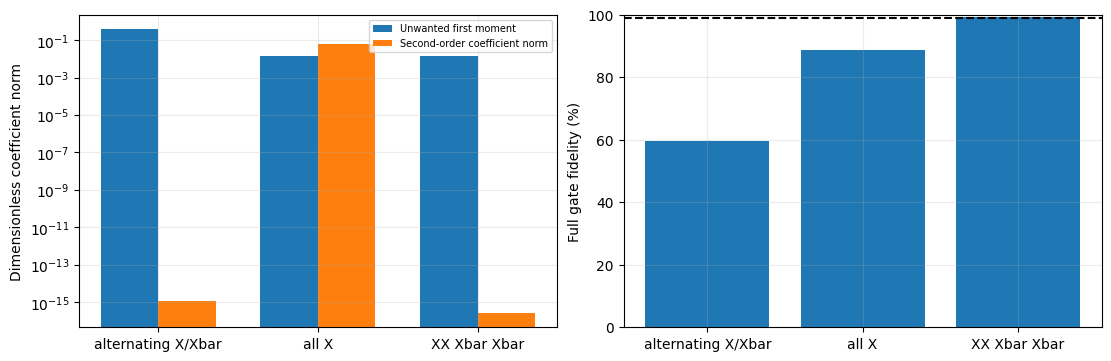

In [2]:

diagnostics=pd.DataFrame(read('cd_finite_pulse_diagnostics.json'));display(diagnostics)
fig,axes=plt.subplots(1,2,figsize=(11,3.5),constrained_layout=True)
x=np.arange(3)
axes[0].bar(x-.18,np.maximum(diagnostics.unwanted_first_moment,1e-16),.36,label='Unwanted first moment')
axes[0].bar(x+.18,np.maximum(diagnostics.quadratic_diagnostic,1e-16),.36,label='Second-order coefficient norm')
axes[0].set(yscale='log',xticks=x,xticklabels=diagnostics.pattern,ylabel='Dimensionless coefficient norm')
axes[0].legend(fontsize=7)
axes[1].bar(x,100*diagnostics.fidelity);axes[1].axhline(99,color='k',ls='--')
axes[1].set(xticks=x,xticklabels=diagnostics.pattern,ylabel='Full gate fidelity (%)',ylim=(0,100))
for ax in axes:ax.grid(alpha=.25)
finish('cd_why_four_pulses')


## 2. The complete reusable sequence

| Pulse within a cycle | Physical qubit DAC phase | Angle | Duration |
|---|---:|---:|---:|
| 1 | 0 degrees | pi | 30 ns |
| 2 | 0 degrees | pi | 30 ns |
| 3 | 180 degrees | pi | 30 ns |
| 4 | 180 degrees | pi | 30 ns |

There are no gaps. Add one 5 ns pump ramp at either end of the entire train.
The pump phase is fixed at **270 degrees**, or 90 degrees for negative beta.
The supplied qubit pi amplitude and envelope stay unchanged.

For $b=|\beta|>0$, the tested rule is

$$K=\left\lceil\max(2.5b,\;2.25b^2)\right\rceil,\qquad
\mathcal A_K=(0.120K+0.005)\,\mu\mathrm{s},$$

$$g_0=\frac{2b}{\mathcal A_K},\qquad
g=g_0(1+c g_0^2),\qquad c=0.0004071933463\,\mu\mathrm{s}^2.$$

Here K is the number of four-pulse cycles and g is in rad/us. The single
correction coefficient c is calibrated at beta=1 and then held fixed.
The target is never redefined using an achieved output.

$$t_{\mathrm{swap}}=\frac{\pi}{2g},\qquad
T_{\mathrm{command}}=0.120K+0.010\;\mu\mathrm{s}.$$

Extra cycles reduce the finite-pulse error as beta and intermediate photon
population grow. The quadratic repeat rule is a tested safeguard, not a
universal error bound. Skip beta=0.

,beta,cycles,pi_pulses,swap_ns,command_ns,gate_fidelity
2,-2.000,9,36,423.733444,1090.0,0.991791
1,-1.000,3,12,283.207905,370.0,0.992278
0,-0.500,2,8,382.252006,250.0,0.998440
3,0.050,1,4,1962.983848,130.0,0.999965
4,0.100,1,4,980.725381,130.0,0.999865
5,0.125,1,4,784.121008,130.0,0.999792
6,0.200,1,4,488.835574,130.0,0.999427
7,0.300,1,4,324.207605,130.0,0.997843
8,0.400,1,4,241.410527,130.0,0.992426
9,0.500,2,8,382.252006,250.0,0.998440


One calibrated coefficient;20signed strengths;360input columns independently checked.


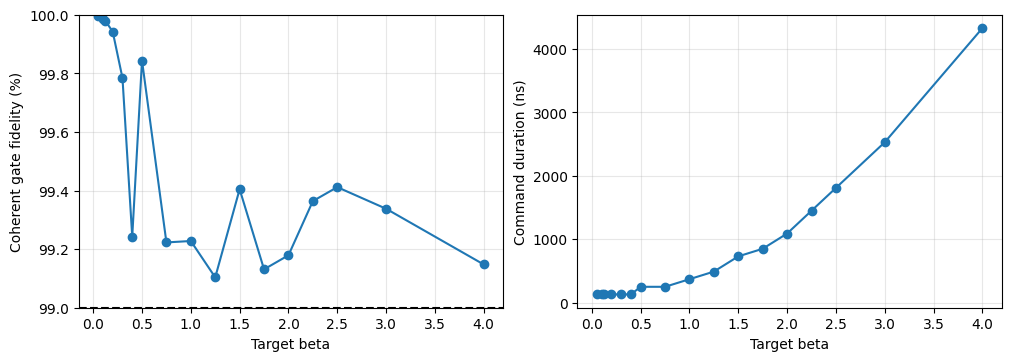

[beta=1 full pulse CSV](runs/constant_pump_gaussian/verified/cd_binary_scaled_b1_sequence.csv)

In [3]:

rule=read('binary_rule_summary.json');rows=[]
for a in rule['results']:
    r=certificate(a['job']['name'])
    rows.append(dict(beta=r['strength'],cycles=a['job']['cycles'],pi_pulses=a['job']['cells'],
                     swap_ns=1000*a['job']['swap'],command_ns=r['command_us']*1000,
                     gate_fidelity=r['fidelity']))
table=pd.DataFrame(rows).sort_values('beta');display(table)
assert len(table)==20 and min(table.gate_fidelity)>.99
print('One calibrated coefficient;20signed strengths;360input columns independently checked.')
fig,axes=plt.subplots(1,2,figsize=(10,3.5),constrained_layout=True)
positive=table[table.beta>0]
axes[0].plot(positive.beta,100*positive.gate_fidelity,'o-');axes[0].axhline(99,color='k',ls='--')
axes[0].set(xlabel='Target beta',ylabel='Coherent gate fidelity (%)',ylim=(99,100))
axes[1].plot(positive.beta,positive.command_ns,'o-')
axes[1].set(xlabel='Target beta',ylabel='Command duration (ns)')
for ax in axes:ax.grid(alpha=.3)
finish('cd_reusable_strength_rule')
display(Markdown('[beta=1 full pulse CSV](runs/constant_pump_gaussian/verified/cd_binary_scaled_b1_sequence.csv)'))


## 3. Programmed waveform, played waveform and the 400 ns gate

For beta=1, three cycles contain 12 pi pulses and take 370 ns to program.
The constant pump needs no internal phase ramp or chirp. The plots retain
the real RFDC delay, with time measured from the beginning of the buffer.

The entire causal filter response lasts 414.22 ns. The gate is already at
**99.2278% fidelity at 400 ns**. Its remaining tail changes the input-subspace
gate operator by less than $8\times10^{-7}$ in spectral norm. We evaluate the
actual evolution at that time; no waveform samples are deleted or reprogrammed.

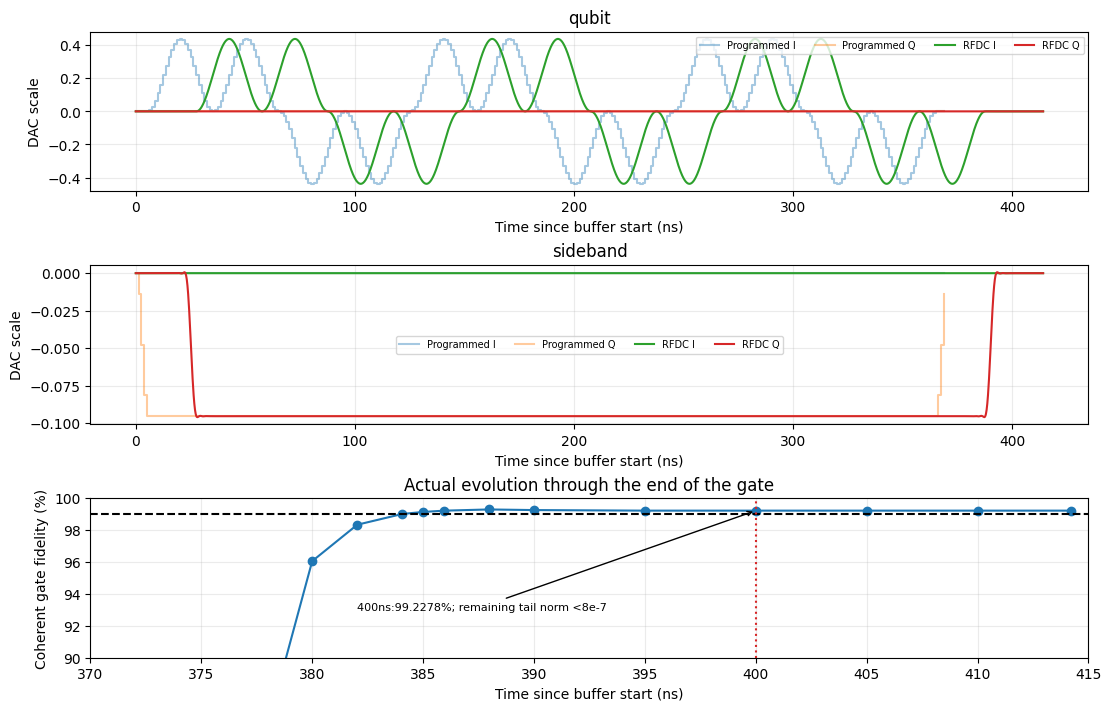

In [4]:

w=np.load(V/'cd_binary_scaled_b1_words.npz')
fig,axes=plt.subplots(3,1,figsize=(11,7),constrained_layout=True)
for ax,key in zip(axes[:2],['qubit','sideband']):
    programmed=sample_to_complex(w[key]);played=hw.rfdc_interpolate(programmed)
    ts=np.arange(len(programmed))*1.25;tf=np.arange(len(played))*.15625
    ax.step(ts,programmed.real,where='post',alpha=.4,label='Programmed I')
    ax.step(ts,programmed.imag,where='post',alpha=.4,label='Programmed Q')
    ax.plot(tf,played.real,label='RFDC I');ax.plot(tf,played.imag,label='RFDC Q')
    ax.set(title=key,xlabel='Time since buffer start (ns)',ylabel='DAC scale');ax.grid(alpha=.25);ax.legend(fontsize=7,ncol=4)

completion=read('cd_completion_curve.json');points=pd.DataFrame(completion['points'])
axes[2].plot(points.time_ns,100*points.fidelity,'o-')
axes[2].axhline(99,color='k',ls='--');axes[2].axvline(400,color='C3',ls=':')
axes[2].set(xlim=(370,415),ylim=(90,100),xlabel='Time since buffer start (ns)',
            ylabel='Coherent gate fidelity (%)',title='Actual evolution through the end of the gate')
axes[2].grid(alpha=.25)
axes[2].annotate('400ns:99.2278%; remaining tail norm <8e-7',(400,99.2278),
                 xytext=(382,93),arrowprops=dict(arrowstyle='->'),fontsize=8)

finish('cd_simple_played_waveform')


## 4. Stronger sidebands: retune and compare

Shorter swap time means stronger coupling. The left plot retunes phases at
each fixed strength, for 310 ns or 370 ns command duration. It compares a
constant pump with smooth 10 ns I/Q transitions. These are achieved local-fit
scores within the stated seed and evaluation budget, not global maxima.

The right plot holds a selected sequence and final frame fixed while varying
strength; it measures calibration sensitivity. The exact-target bound
$|d\langle a\rangle/dt|\le |g|/2$ explains why a weak sideband cannot create
a large CD arbitrarily quickly. It is not itself a 99% process-fidelity bound.

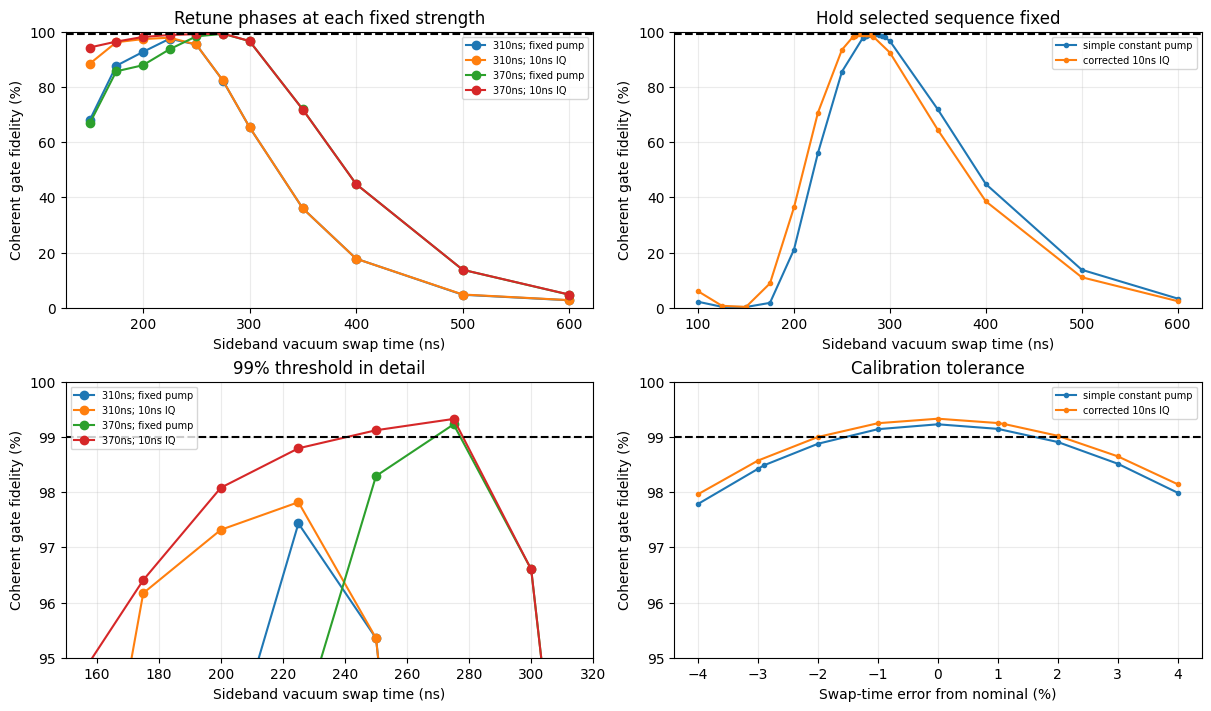

Actual-playback fixed-strength fits: 44 ;each includes all18inputs.
Enumerated 2728 binary X/Xbar words, modulo exact global-sign symmetry.
Also tested 20 fractional-angle cases;best F= 0.9587431395047017
The tested 8/10-pulse schemes did not reach99%;this does not prove impossibility.


In [5]:

scan=pd.DataFrame(read('strength_played_summary.json'))
fig,axes=plt.subplots(2,2,figsize=(12,7),constrained_layout=True)
for cells in [10,12]:
    for pump in [False,True]:
        group=[r for r in read('strength_played_summary.json') if r['job']['cells']==cells and r['job']['pump_control']==pump]
        group=sorted(group,key=lambda r:r['equivalent_swap_ns'])
        for ax in axes[:,0]:
            ax.plot([r['equivalent_swap_ns'] for r in group],[100*r.get('converged_fidelity',r['fidelity']) for r in group],
                    'o-',label=f'{cells*30+10}ns; '+('10ns IQ' if pump else 'fixed pump'))
for item in read('strength_sensitivity.json')['results']:
    if item['gate']!='cd':continue
    data=pd.DataFrame(item['results']).sort_values('swap_ns')
    label='simple constant pump' if 'binary' in item['name'] else 'corrected 10ns IQ'
    axes[0,1].plot(data.swap_ns,100*data.fidelity,'o-',ms=3,label=label)
    nominal=item['nominal_swap_ns'];near=data[abs(data.swap_ns/nominal-1)<.05]
    axes[1,1].plot(100*(near.swap_ns/nominal-1),100*near.fidelity,'o-',ms=3,label=label)
for ax in axes.ravel():
    ax.axhline(99,color='k',ls='--');ax.grid(alpha=.25);ax.legend(fontsize=7)
    ax.set(xlabel='Sideband vacuum swap time (ns)',ylabel='Coherent gate fidelity (%)',ylim=(0,100))
axes[0,0].set_title('Retune phases at each fixed strength');axes[0,1].set_title('Hold selected sequence fixed')
axes[1,0].set(ylim=(95,100),xlim=(150,320),title='99% threshold in detail')
axes[1,1].set(ylim=(95,100),xlabel='Swap-time error from nominal (%)',title='Calibration tolerance')
finish('cd_strength_comparison')
print('Actual-playback fixed-strength fits:',len(scan),';each includes all18inputs.')
binary=read('binary_cd_summary.json');angles=read('angles_played_summary.json')
print('Enumerated',binary['unique_patterns'],'binary X/Xbar words, modulo exact global-sign symmetry.')
print('Also tested',len(angles),'fractional-angle cases;best F=',max(r['fidelity'] for r in angles))
print('The tested 8/10-pulse schemes did not reach99%;this does not prove impossibility.')


## 5. Fresh independent simulation

The next cell reloads the beta=1 words and propagates all 18 columns with the
independent order-16 solver. The family also passes automatic output/target
cutoff convergence. Individual basis-input errors remain visible: the 99%
goal is coherent process fidelity, rather than a worst-input guarantee.

FRESH INDEPENDENT REPLAY cd_binary_scaled_b1 18inputcolumns; 3456 amplitudes;maxdifference 1.1657341758564144e-15 F 0.9922779449668542


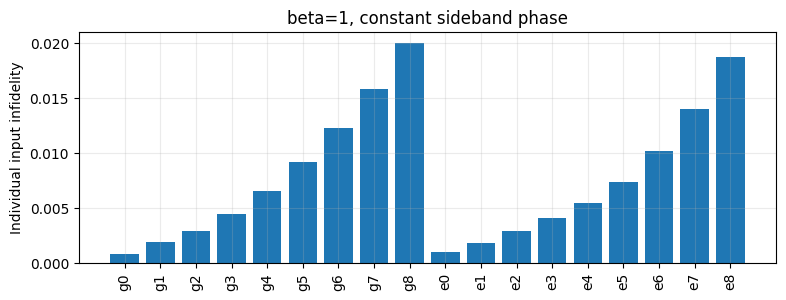

FRESH ACTUAL400ns CHECK:18inputs; 3456 amplitudes;F 0.9922779408792164 remainingtail operatornorm 7.801061008863723e-07


In [6]:

r,out,T=replay('cd_binary_scaled_b1')
fig,ax=plt.subplots(figsize=(9,3))
ax.bar(np.arange(18),1-abs(np.sum(T.conj()*out,axis=0))**2)
ax.set_xticks(range(18),[f'g{n}' for n in range(9)]+[f'e{n}' for n in range(9)],rotation=90)
ax.set(ylabel='Individual input infidelity',title='beta=1, constant sideband phase');ax.grid(alpha=.25)
finish('cd_individual_inputs')

qs,ss=hw.dac_scales(.6);words=np.load(V/'cd_binary_scaled_b1_words.npz')
q=hw.rfdc_interpolate(sample_to_complex(words['qubit'])).conj()/qs*(np.pi/cd.PI_TIME)
s=hw.rfdc_interpolate(sample_to_complex(words['sideband']))/ss*(np.pi/(2*.6))
space=cd.Space(r['levels'],9);initial=np.eye(2*r['levels'],dtype=complex)[:,space.inputs]
count=round(.400/(cd.DT/8))
at400=hw.propagate(q[:count],s[:count],initial,cd.DT/8,order=16)
F400=float(abs(np.vdot(T,at400)/18)**2)
tail=float(np.linalg.norm(out-at400,2))
completion=read('cd_completion_curve.json')
assert abs(F400-completion['independent_fidelity'])<1e-12 and tail<1e-6
print('FRESH ACTUAL400ns CHECK:18inputs;',at400.size,'amplitudes;F',F400,
      'remainingtail operatornorm',tail)


The simple four-pulse word and one calibrated strength rule give a compact
family. At beta=1, pump-phase corrections improve 99.23% to 99.33% at the same
duration, so the fixed-phase word is the simpler choice for a 99% goal.

The tested faster 8/10-pulse alternatives remain below 99%; this does not prove
impossibility. The [README](../README.md) links exact words, the calibration
coefficient and counted search coverage.